# Laboratorio de clasificación 3

|                |   |
:----------------|---|
| **Nombre**     |  Alexa Bojorquez Valdivia  |
| **Fecha**      |  18 de octubre  |
| **Expediente** |  745497 | 

Una regresión logística simple toma **P** predictores y usa una función no lineal para convertir la respuesta binaria **Y** en probabilidades entre $0$ y $1$.

La visualización de este escenario es puntos separados por una línea recta.

<center><img src="https://wirelesspi.com/wp-content/uploads/2022/08/figure-logistic-regression-decision-boundary-2-570x550.png"></center>

Para casos donde los datos no son linealmente separables usamos el truco del kernel para mapear los datos a un espacio de Hilbert.

Imagina un escenario donde tienes dos predictores $x_1, x_2$ y la salida de estos predictores se comporta de esta manera:

| **$x_1$** | **$x_2$** | Salida |
:-----------|-----------|--------|
| 0         | 0         | 0      |
| 0         | 1         | 1      |
| 1         | 0         | 1      |
| 1         | 1         | 0      |


Imagínalo como el interruptos de luz de un foco en una escalera. Se puede prender y apagar desde arriba y desde abajo.

<center><img src="https://www.researchgate.net/profile/Brian-Spears/publication/322048911/figure/fig4/AS:667820685807618@1536232267250/The-exclusive-or-XOR-function-is-a-nonlinear-function-that-returns-0-when-its-two.png"></center>

¿Cómo podemos separar estos datos usando sólo regresión logística? Sin importar cómo usemos una sola línea, nunca se van a poder separar todos los casos, por lo que tendríamos situaciones donde siempre habría error. 

Solución: ¿Por qué nos estamos limitando a una sola línea?

<center><img src="https://pabloinsente.github.io/assets/post-5/XOR-linear.png"></center>

La regresión logística sola es un método de aprendizaje estadístico convexo. Combinar dos regresiones logísticas para clasificar datos no linealmente separables convierte el problema a uno no convexo. ¿Por qué?

- Una regresión logística tiene una función convexa, pero al combinar varias regresiones se agregan más parámetros y relaciones entre ellos, esto hace que la función pueda tener diferentes mínimos y deje de ser convexa.

¿Qué significa que una función sea convexa?

- Una función convexa tiene una forma donde existe un solo mínimo global. Esto hace que al buscar el valor mínimo podamos llegar a la mejor solución sin quedar atrapados en otros mínimos.

¿Por qué nos importa que una función sea convexa o no? ¿Qué impacto tiene para los resultados?

- Porque en una función convexa es más fácil encontrar la mejor solución. En una función no convexa pueden existir diferentes mínimos, por lo que el resultado puede depender del punto desde donde comienza el proceso de optimización.

## Ejercicio 1

Utilizaremos el clasificador `MLPClassifier` de la librería `sklearn`.

Entra a la documentación y describe cómo funciona este objeto (qué entradas necesita, qué salidas da, descripción de sus hiperparámetros).

In [43]:
from sklearn.neural_network import MLPClassifier

In [44]:
MLPClassifier?

Init signature:
MLPClassifier(
    hidden_layer_sizes=(100,),
    activation='relu',
    *,
    solver='adam',
    alpha=0.0001,
    batch_size='auto',
    learning_rate='constant',
    learning_rate_init=0.001,
    power_t=0.5,
    max_iter=200,
    shuffle=True,
    random_state=None,
    tol=0.0001,
    verbose=False,
    warm_start=False,
    momentum=0.9,
    nesterovs_momentum=True,
    early_stopping=False,
    validation_fraction=0.1,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-08,
    n_iter_no_change=10,
    max_fun=15000,
)
Docstring:     
Multi-layer Perceptron classifier.

This model optimizes the log-loss function using LBFGS or stochastic
gradient descent.

.. versionadded:: 0.18

Parameters
----------
hidden_layer_sizes : array-like of shape(n_layers - 2,), default=(100,)
    The ith element represents the number of neurons in the ith
    hidden layer.

activation : {'identity', 'logistic', 'tanh', 'relu'}, default='relu'
    Activation function for the hidden laye

In [45]:
MLPClassifier.fit?

Signature: MLPClassifier.fit(self, X, y, sample_weight=None)
Docstring:
Fit the model to data matrix X and target(s) y.

Parameters
----------
X : ndarray or sparse matrix of shape (n_samples, n_features)
    The input data.

y : ndarray of shape (n_samples,) or (n_samples, n_outputs)
    The target values (class labels in classification, real numbers in
    regression).

sample_weight : array-like of shape (n_samples,), default=None
    Sample weights.

    .. versionadded:: 1.7

Returns
-------
self : object
    Returns a trained MLP model.
File:      /opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py
Type:      function

- MLPClassifier es un modelo de clasificación basado en una red de perceptrones. Recibe las variables independientes X y las categorías que queremos predecir y. Después de entrenarlo con .fit(), podemos utilizar .predict() para obtener la clase predicha.
Algunos de sus principales hiperparámetros son:
- hidden_layer_sizes: define la cantidad de capas ocultas y neuronas.
- activation: función de activación utilizada por las neuronas.
- solver: método utilizado para ajustar los pesos.
- alpha: controla la penalización del modelo.
- learning_rate_init: define el tamaño inicial de los cambios durante el aprendizaje.
- max_iter: número máximo de iteraciones utilizadas para entrenar.
- random_state: permite obtener resultados reproducibles.

## Ejercicio 2

Utiliza el objeto de perceptrón multicapa para clasificar si un tumor es maligno o benigno con el dataset `Brain Tumor Dataset`. Utiliza un cross-validation de train-test de 70/30. Sigue todos los pasos de EDA y limpieza vistos.

In [46]:
import pandas as pd                        
import numpy as np                          
import matplotlib.pyplot as plt                       

data = pd.read_csv("brain_tumor_dataset.csv", skiprows=1)  # Omite la primera línea extra

data.head()                             

,Patient_ID,Age,Gender,Tumor_Type,Tumor_Size,Location,Histology,Stage,Symptom_1,Symptom_2,Symptom_3,Radiation_Treatment,Surgery_Performed,Chemotherapy,Survival_Rate,Tumor_Growth_Rate,Family_History,MRI_Result,Follow_Up_Required
0,1,73,Male,Malignant,5.375612,Temporal,Astrocytoma,III,Vision Issues,Seizures,Seizures,No,No,No,51.312579,0.111876,No,Positive,Yes
1,2,26,Male,Benign,4.847098,Parietal,Glioblastoma,II,Headache,Headache,Nausea,Yes,Yes,Yes,46.373273,2.165736,Yes,Positive,Yes
2,3,31,Male,Benign,5.588391,Parietal,Meningioma,I,Vision Issues,Headache,Seizures,No,No,No,47.072221,1.884228,No,Negative,No
3,4,29,Male,Malignant,1.436600,Temporal,Medulloblastoma,IV,Vision Issues,Seizures,Headache,Yes,No,Yes,51.853634,1.283342,Yes,Negative,No
4,5,54,Female,Benign,2.417506,Parietal,Glioblastoma,I,Headache,Headache,Seizures,No,No,Yes,54.708987,2.069477,No,Positive,Yes


In [47]:
print(data.shape)      
print(data.columns)     
data.info()             

(20000, 19)
Index(['Patient_ID', 'Age', 'Gender', 'Tumor_Type', 'Tumor_Size', 'Location',
       'Histology', 'Stage', 'Symptom_1', 'Symptom_2', 'Symptom_3',
       'Radiation_Treatment', 'Surgery_Performed', 'Chemotherapy',
       'Survival_Rate', 'Tumor_Growth_Rate', 'Family_History', 'MRI_Result',
       'Follow_Up_Required'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Patient_ID           20000 non-null  int64  
 1   Age                  20000 non-null  int64  
 2   Gender               20000 non-null  str    
 3   Tumor_Type           20000 non-null  str    
 4   Tumor_Size           20000 non-null  float64
 5   Location             20000 non-null  str    
 6   Histology            20000 non-null  str    
 7   Stage                20000 non-null  str    
 8   Symptom_1            20000 non-null  str    
 

In [48]:
data.describe()

,Patient_ID,Age,Tumor_Size,Survival_Rate,Tumor_Growth_Rate
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,49.433700,5.236552,70.131699,1.547701
std,5773.647028,17.389296,2.754359,17.270834,0.835995
min,1.000000,20.000000,0.500410,40.002386,0.100017
25%,5000.750000,34.000000,2.836686,55.224439,0.830433
50%,10000.500000,49.000000,5.200675,70.305066,1.541821
75%,15000.250000,65.000000,7.624299,85.043395,2.262484
max,20000.000000,79.000000,9.999420,99.998125,2.999835


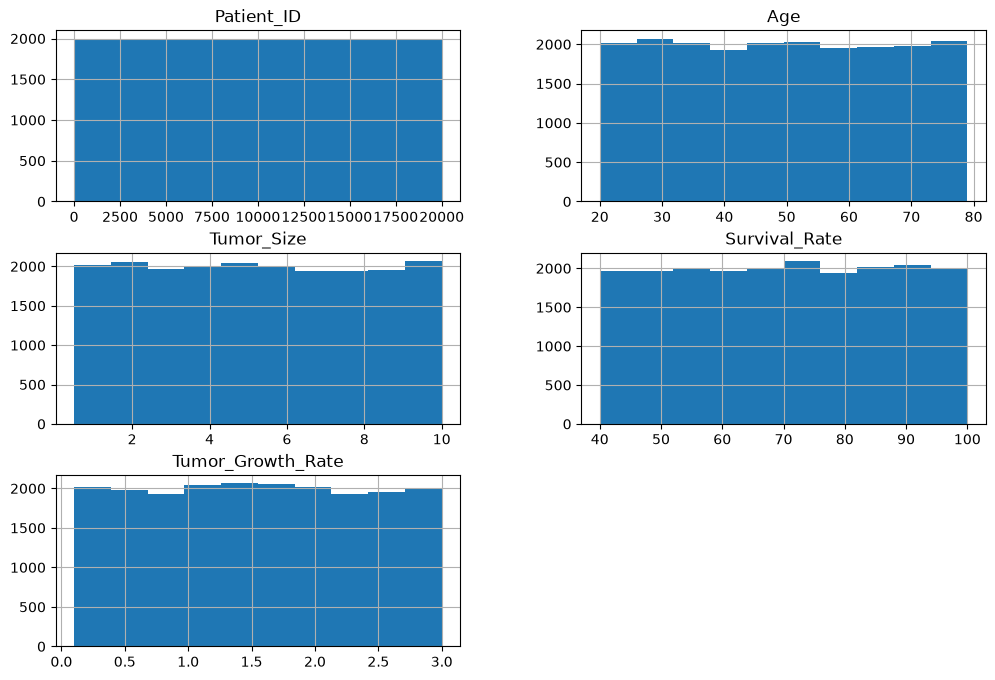

In [49]:
data.hist(figsize=(12, 8))
plt.show()

In [50]:
data = data.drop(columns=['Patient_ID'])   # Elimina el identificador

Elimine Patient_ID porque únicamente identifica a cada paciente y no representa una característica que ayude a clasificar el tipo de tumor.

In [51]:
print(data['Gender'].value_counts())
print(data['Tumor_Type'].value_counts())
print(data['Location'].value_counts())
print(data['Histology'].value_counts())
print(data['Stage'].value_counts())

Gender
Female    10016
Male       9984
Name: count, dtype: int64
Tumor_Type
Malignant    10030
Benign        9970
Name: count, dtype: int64
Location
Temporal     5118
Parietal     4990
Occipital    4967
Frontal      4925
Name: count, dtype: int64
Histology
Glioblastoma       5068
Meningioma         5016
Medulloblastoma    4979
Astrocytoma        4937
Name: count, dtype: int64
Stage
II     5093
I      4986
IV     4968
III    4953
Name: count, dtype: int64


In [52]:
print(data['Radiation_Treatment'].value_counts())
print(data['Surgery_Performed'].value_counts())
print(data['Chemotherapy'].value_counts())
print(data['Family_History'].value_counts())
print(data['MRI_Result'].value_counts())
print(data['Follow_Up_Required'].value_counts())

Radiation_Treatment
Yes    10021
No      9979
Name: count, dtype: int64
Surgery_Performed
Yes    10060
No      9940
Name: count, dtype: int64
Chemotherapy
Yes    10097
No      9903
Name: count, dtype: int64
Family_History
No     10002
Yes     9998
Name: count, dtype: int64
MRI_Result
Positive    10029
Negative     9971
Name: count, dtype: int64
Follow_Up_Required
Yes    10101
No      9899
Name: count, dtype: int64


In [53]:
data['Tumor_Type'].value_counts()

Tumor_Type
Malignant    10030
Benign        9970
Name: count, dtype: int64

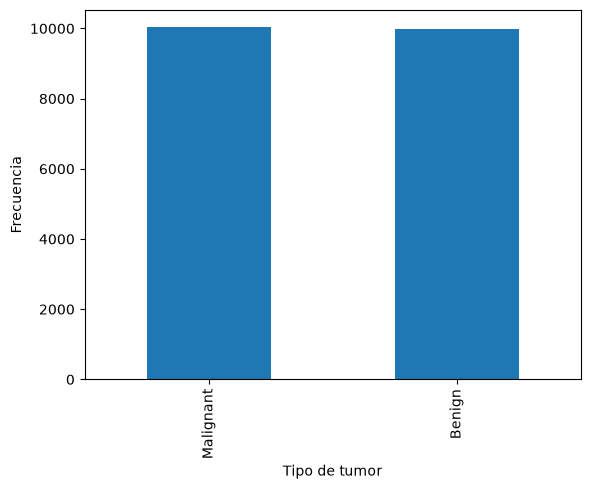

In [54]:
data['Tumor_Type'].value_counts().plot(kind='bar')
plt.xlabel('Tipo de tumor')
plt.ylabel('Frecuencia')
plt.show()

¿Qué métrico crees que sea mejor para este ejercicio? Escoge los 3 métricos que crees más apropiados para esta predicción, argumenta en pro y en contra del top 3. Elige uno para optimizar (justifica tu respuesta).

In [55]:
data['Tumor_Type'] = data['Tumor_Type'].map({'Benign': 0, 'Malignant': 1})

data['Gender'] = data['Gender'].map({'Female': 0, 'Male': 1})

data['Radiation_Treatment'] = data['Radiation_Treatment'].map({'No': 0, 'Yes': 1})
data['Surgery_Performed'] = data['Surgery_Performed'].map({'No': 0, 'Yes': 1})
data['Chemotherapy'] = data['Chemotherapy'].map({'No': 0, 'Yes': 1})
data['Family_History'] = data['Family_History'].map({'No': 0, 'Yes': 1})
data['Follow_Up_Required'] = data['Follow_Up_Required'].map({'No': 0, 'Yes': 1})

data['MRI_Result'] = data['MRI_Result'].map({'Negative': 0, 'Positive': 1})

In [56]:
data['Stage'] = data['Stage'].map({
    'I': 1,
    'II': 2,
    'III': 3,
    'IV': 4
})

In [57]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  20000 non-null  int64  
 1   Gender               20000 non-null  int64  
 2   Tumor_Type           20000 non-null  int64  
 3   Tumor_Size           20000 non-null  float64
 4   Location             20000 non-null  str    
 5   Histology            20000 non-null  str    
 6   Stage                20000 non-null  int64  
 7   Symptom_1            20000 non-null  str    
 8   Symptom_2            20000 non-null  str    
 9   Symptom_3            20000 non-null  str    
 10  Radiation_Treatment  20000 non-null  int64  
 11  Surgery_Performed    20000 non-null  int64  
 12  Chemotherapy         20000 non-null  int64  
 13  Survival_Rate        20000 non-null  float64
 14  Tumor_Growth_Rate    20000 non-null  float64
 15  Family_History       20000 non-null  int64  
 1

In [58]:
categoricas = ['Location', 'Histology', 'Symptom_1', 'Symptom_2', 'Symptom_3']

In [59]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)

categoricas_encoded = encoder.fit_transform(data[categoricas])

In [60]:
categoricas_encoded = pd.DataFrame(
    categoricas_encoded,
    columns=encoder.get_feature_names_out(categoricas)
)

In [61]:
data = data.drop(columns=categoricas)
data = pd.concat([data, categoricas_encoded], axis=1)

In [62]:
X = data.drop(columns=['Tumor_Type'])
y = data['Tumor_Type']

In [63]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(14000, 32)
(6000, 32)


In [64]:
from sklearn.neural_network import MLPClassifier

modelo = MLPClassifier(random_state=42)

In [66]:
modelo.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",200
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [67]:
y_pred = modelo.predict(X_test)

In [68]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)

Accuracy: 0.49316666666666664
Precision: 0.4993160054719562
Recall: 0.36043449637919683


Accuracy: mide la proporción total de predicciones correctas. Es fácil de interpretar y en este caso es útil porque las clases están balanceadas. Como desventaja, no nos indica específicamente qué tan bien detectamos los tumores malignos. El modelo obtuvo un accuracy de 0.4932.

Precision: indica qué proporción de los tumores que el modelo clasificó como malignos realmente eran malignos. Es útil para controlar los falsos positivos, pero no considera directamente los tumores malignos que no fueron detectados. El modelo obtuvo un precision de 0.4993.

Recall: indica qué proporción de los tumores que realmente eran malignos fueron identificados correctamente. Su ventaja es que permite enfocarnos en evitar falsos negativos, aunque puede aumentar los falsos positivos. El modelo obtuvo un recall de 0.3604.

Para este problema elegi Recall como el métrico a optimizar, ya que considero más importante detectar la mayor cantidad posible de tumores malignos.

## Ejercicio 3

Modifica los hiperparámetros para elevar el métrico elegido. Intenta con 10 sets de hiperparámetros distintos. Crea una tabla que muestre los resultados.

In [80]:
#50 neuronas
modelo1 = MLPClassifier(
    hidden_layer_sizes=(50,),
    random_state=42
)

modelo1.fit(X_train, y_train)

y_pred1 = modelo1.predict(X_test)

recall1 = recall_score(y_test, y_pred1)

print("Recall modelo 1:", recall1)

Recall modelo 1: 0.716589861751152


In [81]:
#100 neuronas
modelo2 = MLPClassifier(
    hidden_layer_sizes=(100,),
    random_state=42
)

modelo2.fit(X_train, y_train)

y_pred2 = modelo2.predict(X_test)

recall2 = recall_score(y_test, y_pred2)

print("Recall modelo 2:", recall2)

Recall modelo 2: 0.36043449637919683


In [82]:
#2 capas ocultas
modelo3 = MLPClassifier(
    hidden_layer_sizes=(50, 50),
    random_state=42
)

modelo3.fit(X_train, y_train)

y_pred3 = modelo3.predict(X_test)

recall3 = recall_score(y_test, y_pred3)

print("Recall modelo 3:", recall3)

Recall modelo 3: 0.21428571428571427


In [83]:
#Activacion de relu a tanh
modelo4 = MLPClassifier(
    hidden_layer_sizes=(50,),
    activation='tanh',
    random_state=42
)

modelo4.fit(X_train, y_train)

y_pred4 = modelo4.predict(X_test)

recall4 = recall_score(y_test, y_pred4)

print("Recall modelo 4:", recall4)

Recall modelo 4: 0.5694535878867676


/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [84]:
#Aumento alpha
modelo5 = MLPClassifier(
    hidden_layer_sizes=(50,),
    activation='relu',
    alpha=0.001,
    random_state=42
)

modelo5.fit(X_train, y_train)

y_pred5 = modelo5.predict(X_test)

recall5 = recall_score(y_test, y_pred5)

print("Recall modelo 5:", recall5)

Recall modelo 5: 0.7195523370638578


In [85]:
#Mayor alpha
modelo6 = MLPClassifier(
    hidden_layer_sizes=(50,),
    activation='relu',
    alpha=0.01,
    random_state=42
)

modelo6.fit(X_train, y_train)

y_pred6 = modelo6.predict(X_test)

recall6 = recall_score(y_test, y_pred6)

print("Recall modelo 6:", recall6)

Recall modelo 6: 0.71724818959842


In [88]:
#Menor learning rate
modelo7 = MLPClassifier(
    hidden_layer_sizes=(50,),
    activation='relu',
    alpha=0.001,
    learning_rate_init=0.0005,
    random_state=42
)

modelo7.fit(X_train, y_train)

y_pred7 = modelo7.predict(X_test)

recall7 = recall_score(y_test, y_pred7)

print("Recall modelo 7:", recall7)

Recall modelo 7: 0.19420671494404212


In [89]:
#Mayor learning rate
modelo8 = MLPClassifier(
    hidden_layer_sizes=(50,),
    activation='relu',
    alpha=0.001,
    learning_rate_init=0.005,
    random_state=42
)

modelo8.fit(X_train, y_train)

y_pred8 = modelo8.predict(X_test)

recall8 = recall_score(y_test, y_pred8)

print("Recall modelo 8:", recall8)

Recall modelo 8: 0.03686635944700461


In [90]:
#Activacion logistic
modelo9 = MLPClassifier(
    hidden_layer_sizes=(50,),
    activation='logistic',
    alpha=0.001,
    random_state=42
)

modelo9.fit(X_train, y_train)

y_pred9 = modelo9.predict(X_test)

recall9 = recall_score(y_test, y_pred9)

print("Recall modelo 9:", recall9)

Recall modelo 9: 0.5032916392363397


/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [91]:
#Más iteraciones
modelo10 = MLPClassifier(
    hidden_layer_sizes=(50,),
    activation='relu',
    alpha=0.001,
    max_iter=500,
    random_state=42
)

modelo10.fit(X_train, y_train)

y_pred10 = modelo10.predict(X_test)

recall10 = recall_score(y_test, y_pred10)

print("Recall modelo 10:", recall10)

Recall modelo 10: 0.7195523370638578


In [92]:
resultados = pd.DataFrame({
    'Modelo': [
        'Modelo 1', 'Modelo 2', 'Modelo 3', 'Modelo 4', 'Modelo 5',
        'Modelo 6', 'Modelo 7', 'Modelo 8', 'Modelo 9', 'Modelo 10'
    ],
    'Recall': [
        recall1, recall2, recall3, recall4, recall5,
        recall6, recall7, recall8, recall9, recall10
    ]
})

resultados

,Modelo,Recall
0,Modelo 1,0.716590
1,Modelo 2,0.360434
2,Modelo 3,0.214286
3,Modelo 4,0.569454
4,Modelo 5,0.719552
5,Modelo 6,0.717248
6,Modelo 7,0.194207
7,Modelo 8,0.036866
8,Modelo 9,0.503292
9,Modelo 10,0.719552


Los mejores resultados fueron los modelos 5 y 10 con un Recall de 0.7196. Como ambos obtuvieron el mismo resultado, elegiría el modelo 5 porque utiliza menos iteraciones. Comparado con el modelo inicial, el Recall aumentó de 0.3604 a 0.7196.